Ready for analysis: loaded 50000 deposition process runs
Domain feature engineering and data preprocessing completed

=== [Step 1] Starting XGBoost hyperparameter optimization search ===
XGBoost surrogate models trained and tuned!
----------------------------------------
Best CV R² score: 0.9485
Best hyperparameters: {'regressor__subsample': 1.0, 'regressor__n_estimators': 200, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.2, 'regressor__gamma': 0.5}
----------------------------------------

=== [Step 2] Staring Inverse Recipe Optimization ===

[Physics-Coupled Optimal Recipe for 100.0 nm/min Target]
----------------------------------------
Temperature      : 304.8 °C
Pressure         : 1.6 Torr
RF Power         : 176.3 W
SiH4 Flow        : 53.1 sccm
N2O Flow         : 1178.6 sccm
Ar Flow          : 1134.6 sccm
Total Gas Flow   : 2366.2 sccm
Plasma Density   : 280.7
----------------------------------------


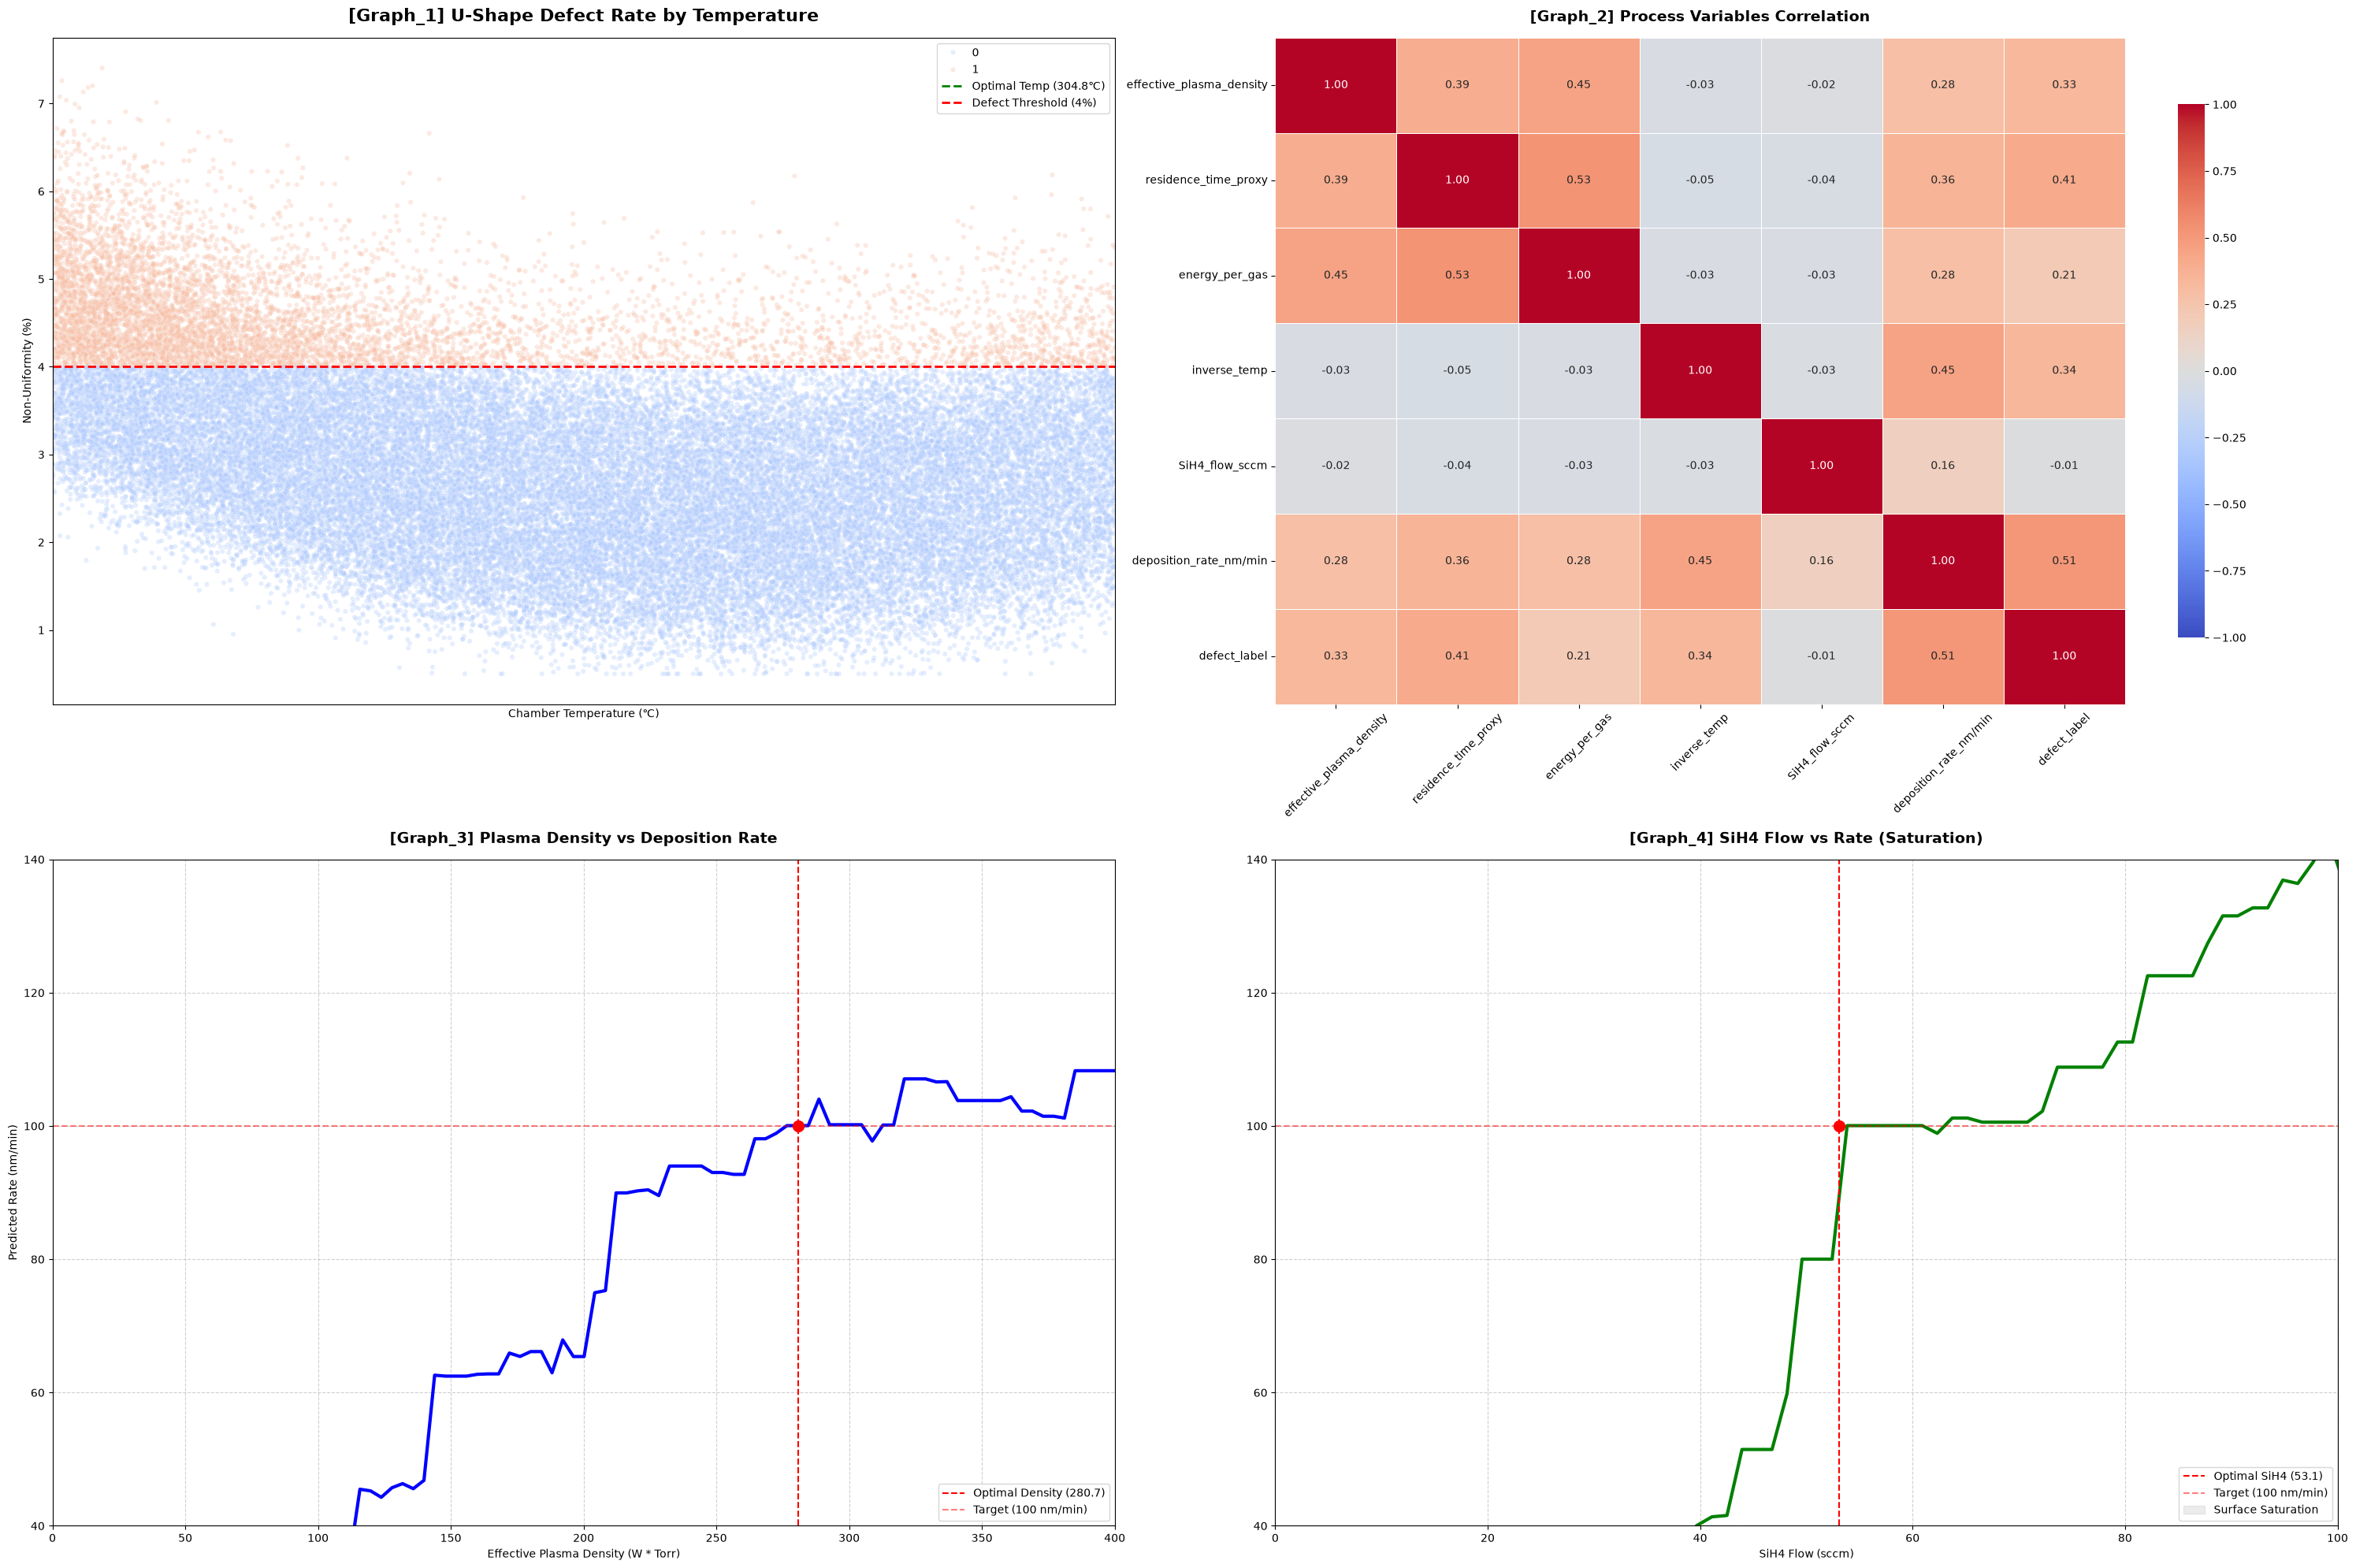

Models and optimal recipe saved successfully!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import seaborn as sns
from scipy.optimize import minimize
from scipy.optimize import differential_evolution
from sklearn.model_selection import RandomizedSearchCV
import warnings
import joblib

# i.   Suppress non-critical runtime/convergence warnings for cleaner notebook output
warnings.filterwarnings('ignore')

# ii.  Load Synthetic PECVD Dataset
df_dep = pd.read_csv("Dataset_sample.csv")
print(f"Ready for analysis: loaded {len(df_dep)} deposition process runs")

# iii. Domain-Informed Feature Engineering
# [1] Define curated featur set (X) upon dataset
# a. Total volumetric gas feed rate (sccm) summed across precursor and diluent lines
df_dep['gas_flow_sccm'] = df_dep['SiH4_flow_sccm'] + df_dep['N2O_flow_sccm'] + df_dep['Ar_flow_sccm'] 

# b. Proxy for effective plasma density/ion flux (scales with RF power and chamber pressure)
df_dep['effective_plasma_density'] = df_dep['power_W'] * df_dep['pressure_torr']

# c. Proxy for gas residence time (higher pressure and lower total flow prolong residence time)
df_dep['residence_time_proxy'] = df_dep['pressure_torr'] / df_dep['gas_flow_sccm']

# d. Specific energy input per unit gas flow (drives precursor dissociation & excitation)
df_dep['energy_per_gas'] = df_dep['power_W'] / df_dep['gas_flow_sccm']

# e. Reciprocal absolute temperature (1/K) for Arrhenius and Van 't Hoff kinetic relationships
df_dep['inverse_temp'] = 1 / (df_dep['temp_C'] + 273.15)

# [2] Define curated feature set (X) and target variables (Y) for ML training
features = ['effective_plasma_density', 'residence_time_proxy', 'energy_per_gas', 'inverse_temp','SiH4_flow_sccm','N2O_flow_sccm','Ar_flow_sccm']
targets = ['deposition_rate_nm/min', 'defect_label']

# [3] Clean infinite values, drop rows with missing required values, and filter out non-positive growth rates
df_dep = df_dep.replace([np.inf, -np.inf], np.nan).dropna(subset=features + targets)
df_dep = df_dep[df_dep['deposition_rate_nm/min'] >= 0]

# [4] Extract feature matrix and target vectors
X = df_dep[features]
y_speed = df_dep['deposition_rate_nm/min']
y_defect = df_dep['defect_label']

# a. Log1p transformation stabilizes variance and handles skewed deposition rate distributions during regression
y_speed_log = np.log1p(y_speed)
print(f"Domain feature engineering and data preprocessing completed\n")

# iv.  Surrogate Model Training & Hyperparameter Optimization
print("=== [Step 1] Starting XGBoost hyperparameter optimization search ===")

# [1] Base XGBoost regressor minimizing squared error (L2 loss) for deposition rate prediction
xgb_base = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)

# [2] Hyperparameter search space designed to regularize tree complexity and mitigate overfitting)
param_grid = {
    'regressor__n_estimators': [100, 200, 300],         # Number of boosting trees
    'regressor__max_depth': [3, 5, 7],                  # Maximum depth per tree (shallower trees reduce overfitting)
    'regressor__learning_rate': [0.01, 0.05, 0.1, 0.2], # Step shrinkage factor applied to each tree's contribution
    'regressor__subsample': [0.8, 1.0],                 # Row subsampling ratio per tree for stochastic regularization
    'regressor__gamma': [0, 0.1, 0.5]                   # Minimum loss reduction required to make a further leaf split
}

# [3] Randomized search with 5-fold cross-validation using R^2 as the selection metric
random_search_xgb = RandomizedSearchCV(
    estimator=xgb_base, 
    param_distributions=param_grid, 
    n_iter=10,        # Number of random parameter combinations sampled
    cv=5,             # 5-fold cross-validation
    scoring='r2',     # Coefficient of determination (R^2)
    n_jobs=-1,        # Utilize all available CPU cores
    random_state=42   # Reproducible sampling
)

# [4] Train deposition rate regressor on log1p-transformed target values to stabilize variance
random_search_xgb.fit(X.values, y_speed_log.values)
best_xgb_speed = random_search_xgb.best_estimator_

# [5] Train XGBoost classifier to estimate process defect probability (defect_label = 0 or 1)
xgb_defect = xgb.XGBClassifier(random_state=42, learning_rate=0.1, n_estimators=100).fit(X, y_defect)
xgb_defect.fit(X.values, y_defect.values)

print("XGBoost surrogate models trained and tuned!")
print("-" * 40)
print(f"Best CV R² score: {random_search_xgb.best_score_:.4f}")
print(f"Best hyperparameters: {random_search_xgb.best_params_}")
print("-" * 40)

# v.   Inverse Recipe Optimization Setup & Objective Evaluation
print("\n=== [Step 2] Staring Inverse Recipe Optimization ===")

# [1] Target deposition rate (nm/min) for inverse process design
target_speed = 100.0 

# [2] Explicit search bounds for the 6 controllable PECVD hardware/recipe parameters
real_bounds = [
    (250, 400),        # Temperature (℃)
    (1.0, 5.0),        # Chamber pressure (Torr)
    (50,  300),        # RF plasma power (W)
    (10.0, 100.0),     # SiH4 precursor flow rate (sccm)
    (200, 2000.0),     # N2O oxidant flow rate (sccm)
    (200, 2000.0)      # Ar diluent/plasma gas flow rate (sccm)
]

# [3] Objective Function for Differential Evolution Inverse Design
def xgb_objective_function(x_array):
    # a. Unpack candidate controllable recipe parameters
    temp_c, pressure, power, sih4, n2o, ar = x_array
    
    # b. Hard safety ceiling on RF power (> 250 W) to penalize aggressive ion bombardment/damage regimes
    if power > 250: 
            return 1e6  

    # c. Gas stoichiometry penalty: enforce N2O/SiH4 molar/flow ratio >= 20 to avoid Si-rich/sub-oxide films
    current_ratio = n2o / sih4 if sih4 > 0 else 0
    ratio_penalty = 0
    if current_ratio < 20:
        ratio_penalty = (20 - current_ratio) * 10000 

    # d. Recompute physics-derived features inside the objective so candidate points stay physically consistent 
    total_flow = sih4 + n2o + ar
    density = power * pressure
    residence = pressure / total_flow
    energy = power / total_flow
    inv_temp = 1 / (temp_c + 273.15)
    
    # e. Use a lightweight 2D NumPy array to speed up per-evaluation inference
    input_data = np.array([[density, residence, energy, inv_temp, sih4, n2o, ar]])
    
    # f. Predict log1p deposition rate, invert back to nm/min via expm1, and compute total objective cost
    pred_speed_log = best_xgb_speed.predict(input_data)[0]
    pred_speed = np.expm1(pred_speed_log)
    speed_error = abs(pred_speed - target_speed)

    # g. Probability of class 1 (defect) predicted by the classification surrogate
    defect_prob = xgb_defect.predict_proba(input_data)[0][1]

    # h. Minimize deposition rate error while heavily penalizing defect likelihood and stoichiometry violations
    return speed_error + (defect_prob * 10000) + ratio_penalty
    
# [4] Reference bounds for engineered feature space (retaining minimum RF power floor assumption of 0.005 W)
min_density = max(X['effective_plasma_density'].min(), 5e-3 * df_dep['pressure_torr'].min())
min_energy = max(X['energy_per_gas'].min(), 5e-3 / df_dep['gas_flow_sccm'].max())
bounds = [
    (min_density, X['effective_plasma_density'].max()),
    (X['residence_time_proxy'].min(), X['residence_time_proxy'].max()),
    (min_energy, X['energy_per_gas'].max()),
    (X['inverse_temp'].min(), X['inverse_temp'].max()),
    (10.0,   100.0), # Bounds for flow rate of SiH4
    (100.0, 2000.0), # Bounds for flow rate of N2O
    (100.0, 2000.0)  # Bounds for flow rate of Ar
]

# [5] Run Differential Evolution global optimizer over controllable recipe bounds
result = differential_evolution(xgb_objective_function, real_bounds, seed=42)

# [6] Extract optimized controllable process recipe
opt_temp, opt_press, opt_power, opt_sih4, opt_n2o, opt_ar = result.x

print("\n[Physics-Coupled Optimal Recipe for 100.0 nm/min Target]")
print("-" * 40)
print(f"Temperature      : {opt_temp:.1f} °C")
print(f"Pressure         : {opt_press:.1f} Torr")
print(f"RF Power         : {opt_power:.1f} W")
print(f"SiH4 Flow        : {opt_sih4:.1f} sccm")
print(f"N2O Flow         : {opt_n2o:.1f} sccm")
print(f"Ar Flow          : {opt_ar:.1f} sccm")
print(f"Total Gas Flow   : {(opt_sih4 + opt_n2o + opt_ar):.1f} sccm")
print(f"Plasma Density   : {(opt_power * opt_press):.1f}")
print("-" * 40)

# vi.  Multi-Panel Diagnostic & Surrogate Validation Plots
# [1] Optimal Recipe & Fixed Feature Baseline
# a. Total gas flow rate (sccm) evaluated at the optimized recipe point
opt_total_flow = opt_sih4 + opt_n2o + opt_ar

# b. Reciprocal absolute temperature (1/K) at the optimized chamber temperature
opt_inverse_temp = 1 / (opt_temp + 273.15)

# c. Residence time proxy at the optimized pressure and total gas flow
opt_residence_time = opt_press / opt_total_flow

# d. Ordered feature schema expected by the trained XGBoost surrogate models
features_list = ['effective_plasma_density', 'residence_time_proxy', 'energy_per_gas', 
                 'inverse_temp', 'SiH4_flow_sccm', 'N2O_flow_sccm', 'Ar_flow_sccm']

# e. Initialize wide 2x2 diagnostic figure canvas
fig, axes = plt.subplots(2, 2, figsize=(30, 20))
plt.subplots_adjust(wspace=0.3, hspace=0.4)

# [2] Temperature vs. Film Non-Uniformity & Defect Regime
# a. Scatter plot of wafer non-uniformity across chamber temperature, colored by binary defect label
sns.scatterplot(x=df_dep['temp_C'], y=df_dep['non_uniformity_pct'], 
                hue=df_dep['defect_label'], palette='coolwarm', alpha=0.3, s=20, ax=axes[0,0])

# b. Reference line for nominal/optimal temperature marker and hard defect specification limit (4.0%)
axes[0,0].axvline(f'Optimal Temp ({opt_temp:.1f}℃)', color='green', linestyle='--', linewidth=2, label=f'Optimal Temp ({opt_temp:.1f}℃)')
axes[0,0].axhline(y=4.0, color='red', linestyle='--', linewidth=2, label='Defect Threshold (4%)')
axes[0,0].set_title('[Graph_1] U-Shape Defect Rate by Temperature', fontsize=16, fontweight='bold', pad=15)
axes[0,0].set_xlabel('Chamber Temperature (℃)')
axes[0,0].set_ylabel('Non-Uniformity (%)')
axes[0,0].set_xlim(250, 400) # Clip x-axis to 250-400 ℃
axes[0,0].legend() 

# [3] Multicollinearity & Target Correlation Heatmap
# a. Subset of engineered features, deposition rate, and defect indicator for correlation inspection
heatmap_cols = ['effective_plasma_density', 'residence_time_proxy', 'energy_per_gas', 
                'inverse_temp', 'SiH4_flow_sccm', 'deposition_rate_nm/min', 'defect_label']

# b. Compute pairwise Pearson correlation matrix across selected process and target variables
corr_matrix = df_dep[heatmap_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, 
            ax=axes[0,1], linewidths=.5, cbar_kws={"shrink": .8})

axes[0,1].set_title('[Graph_2] Process Variables Correlation', fontsize=14, fontweight='bold', pad=15)
axes[0,1].tick_params(axis='x', rotation=45)

# [4] Plasma Density vs. Deposition Rate (Surrogate Sweep)
# a. Sweep RF power from 50 W to 300 W while holding other recipe parameters at optimal values
power_range = np.linspace(50, 300, 100)
density_x, density_y = [], []

# b-1. Sweep RF power to evaluate predicted deposition rate across effective plasma density
for p in power_range:
    # b-2. Recompute power-dependent derived features at fixed optimal pressure and total flow
    curr_density = p * opt_press
    curr_energy = p / opt_total_flow

    # b-3. Assemble single-sample feature vector matching training column order
    input_data = np.array([[curr_density, opt_residence_time, curr_energy, 
                            opt_inverse_temp, opt_sih4, opt_n2o, opt_ar]])

    # b-4. Predict log1p deposition rate and invert back to nm/min via expm1
    pred_log = best_xgb_speed.predict(input_data)[0]
    density_y.append(np.expm1(pred_log))
    density_x.append(curr_density)

# c. Plot predicted deposition rate curve and highlight the optimal operating point & 100 nm/min target
axes[1,0].plot(density_x, density_y, 'b-', linewidth=3)
golden_density = opt_power * opt_press
axes[1,0].axvline(x=golden_density, color='red', linestyle='--', label=f'Optimal Density ({golden_density:.1f})')
axes[1,0].axhline(y=100.0, color='red', linestyle='--', alpha=0.5, label='Target (100 nm/min)')
axes[1,0].scatter([golden_density], [100.0], color='red', s=100, zorder=5)
axes[1,0].set_title('[Graph_3] Plasma Density vs Deposition Rate', fontsize=14, fontweight='bold', pad=15)
axes[1,0].set_xlabel('Effective Plasma Density (W * Torr)')
axes[1,0].set_ylabel('Predicted Rate (nm/min)')
axes[1,0].set_ylim(40, 140) # Clip y-axis to 40-140 nm/min
axes[1,0].set_xlim(0, 400)  # Clip x-axis to 0-400 W * Torr
axes[1,0].grid(True, linestyle='--', alpha=0.6)
axes[1,0].legend(loc='lower right')


# [5] SiH4 Flow vs. Deposition Rate (Saturation Check)
# a. Sweep SiH4 flow rate from 10 to 150 sccm to inspect precursor/site saturation behavior
sih4_range = np.linspace(10, 150, 100)
sih4_x, sih4_y = [], []

# b-1. Sweep SiH4 flow rate to evaluate predicted deposition rate and surface saturation trend
for s in sih4_range:
    # b-2. Update total flow, residence time proxy, and specific energy as SiH4 flow varies
    curr_total = s + opt_n2o + opt_ar
    curr_residence = opt_press / curr_total
    curr_energy = opt_power / curr_total
    input_data = np.array([[opt_power * opt_press, curr_residence, curr_energy, 
                            opt_inverse_temp, s, opt_n2o, opt_ar]])

    # b-3. Predict deposition rate (nm/min) from log1p surrogate output
    pred_log = best_xgb_speed.predict(input_data)[0]
    sih4_y.append(np.expm1(pred_log))
    sih4_x.append(s)

# c. Plot SiH4 response curve, mark optimal SiH4 flow, and shade extended flow region above 100 sccm
axes[1,1].plot(sih4_x, sih4_y, 'g-', linewidth=3)
axes[1,1].axvline(x=opt_sih4, color='red', linestyle='--', label=f'Optimal SiH4 ({opt_sih4:.1f})')
axes[1,1].axhline(y=100.0, color='red', linestyle='--', alpha=0.5, label='Target (100 nm/min)')
axes[1,1].scatter([opt_sih4], [100.0], color='red', s=100, zorder=5)
axes[1,1].axvspan(100, 150, color='gray', alpha=0.15, label='Surface Saturation')
axes[1,1].set_title('[Graph_4] SiH4 Flow vs Rate (Saturation)', fontsize=14, fontweight='bold', pad=15)
axes[1,1].set_xlabel('SiH4 Flow (sccm)')
axes[1,1].set_xlim(0, 100)  # Clip x-axis to 0-100 sccm
axes[1,1].set_ylim(40, 140) # Clip y-axis to 40-140 nm/min
axes[1,1].grid(True, linestyle='--', alpha=0.6)
axes[1,1].legend(loc='lower right')

# [6] Print Plots
plt.tight_layout()
plt.show()

# vii. Save optimized recipe parameters, deposition rate regressor, and defect classifier to disk
# [1] Define optimal results
optimal_results = {
    'opt_temp': opt_temp,      # Optimized wafer/chamber temperature (°C)
    'opt_press': opt_press,    # Optimized chamber pressure (Torr)
    'opt_power': opt_power,    # Optimized RF plasma power (W)
    'opt_sih4': opt_sih4,      # Optimized SiH4 precursor flow rate (sccm)
    'opt_n2o': opt_n2o,        # Optimized N2O oxidant flow rate (sccm)
    'opt_ar': opt_ar           # Optimized Ar gas flow rate (sccm)
}
# [2] Serialize optimization dictionary and trained XGBoost models via joblib for downstream reuse/inference
joblib.dump(optimal_results, 'optimal_recipe_params.pkl')
joblib.dump(best_xgb_speed, 'xgb_speed_model.pkl')
joblib.dump(xgb_defect, 'xgb_defect_model.pkl')
print("Models and optimal recipe saved successfully!")